In [1]:
%load_ext jupyter_black

# Index


<div class="alert alert-block alert-info" style="margin-top: 20px">

<font size = 4>
1. <a href="#Imports">Imports</a><br>
2. <a href="#Data-preparation">Data preparation</a><br>
3. <a href="#Model-training">Model training</a><br>
4. <a href="#External-validation">External validation</a><br>

</font>
</div>

# Imports

In [2]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from catboost import CatBoostClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    balanced_accuracy_score,
    recall_score,
)
from sklearn.preprocessing import StandardScaler

sns.set(style="white", color_codes=True, palette="colorblind", font_scale=1)

# Data preparation

In [3]:
dilirank2 = pd.read_excel(
    "../data/Supporting Information 2.xlsx",
    sheet_name="Table S5 - DILIrank 2.0",
)

dilirank2.shape

(838, 139)

In [4]:
dilirank2.drop(
    columns=[
        "LTKBID",
        "SMILES",
        "InChIKey",
        # "Compound Name",
        "DILI Concern",
        "Drug Formulation",
        "Canonical SMILES",
        "Canonical InChIKey",
        "Stereoisomerism",
        "Tautomers at pH7.4 above 10% abundance",
        "Protomers at pH7.4 above 10% abundance",
        # "Normalised pH7.4 SMILES",
        # "Normalised pH7.4 InChIKey",
        "Ionic Character",
        # "DILI Class",
    ],
    inplace=True,
)

dilirank2.sort_values(by=["Normalised pH7.4 InChIKey"], inplace=True)

dilirank2.shape

(838, 128)

In [5]:
training_set = dilirank2[dilirank2["Set"] == "training"]
training_set.reset_index(drop=True, inplace=True)
training_set.drop(columns=["Set"]).copy()

test_set = dilirank2[dilirank2["Set"] == "test"]
test_set.reset_index(drop=True, inplace=True)
test_set.drop(columns=["Set"]).copy()

training_set.shape, test_set.shape

((698, 128), (140, 128))

In [6]:
volsurf_cols = [
    "V",
    "S",
    "R",
    "G",
    "d",
    "W1",
    "W2",
    "W3",
    "W4",
    "W5",
    "W6",
    "W7",
    "W8",
    "D1",
    "D2",
    "D3",
    "D4",
    "D5",
    "D6",
    "D7",
    "D8",
    "WO1",
    "WO2",
    "WO3",
    "WO4",
    "WO5",
    "WO6",
    "WN1",
    "WN2",
    "WN3",
    "WN4",
    "WN5",
    "WN6",
    "IW1",
    "IW2",
    "IW3",
    "IW4",
    "CW1",
    "CW2",
    "CW4",
    "CW5",
    "CW6",
    "CW7",
    "CW8",
    "ID1",
    "ID2",
    "ID3",
    "ID4",
    "CD1",
    "CD2",
    "CD3",
    "CD4",
    "CD5",
    "CD6",
    "CD7",
    "CD8",
    "HL1",
    "HL2",
    "A",
    "CP",
    "POL",
    "MW",
    "FLEX",
    "FLEX_RB",
    "NCC",
    "DIFF",
    "SE",
    "SE0",
    "SE1",
    "LOGP n-Oct",
    "LOGP c-Hex",
    "PSA",
    "HSA",
    "PSAR",
    "PHSAR",
    "LgD5",
    "LgD6",
    "LgD7",
    "LgD7.5",
    "LgD8",
    "LgD9",
    "LgD10",
    "AUS7.4",
    "%FU4",
    "%FU5",
    "%FU6",
    "%FU7",
    "%FU8",
    "%FU9",
    "%FU10",
    "SOLY",
    "LgS3",
    "LgS4",
    "LgS5",
    "LgS6",
    "LgS7",
    "LgS7.5",
    "LgS8",
    "LgS9",
    "LgS10",
    "LgS11",
    "MpKaA",
    "mpKaB",
    "PB",
    "VD",
    "CACO2",
    "SKIN",
    "LgBB",
    "MetStab",
    "HTSflag",
    "C1",
    "C2",
    "C3",
    "C4",
    "C5",
    "P1",
    "P2",
    "P3",
    "P4",
    "P5",
    "EMDIF",
    "EMDIS",
]

In [7]:
scaler = StandardScaler()

X_training = training_set.loc[:, volsurf_cols]
X_test = test_set.loc[:, volsurf_cols]

X_training_scaled = scaler.fit_transform(X_training)
X_test_scaled = scaler.transform(X_test)

In [8]:
y_training = training_set["DILI Class"].tolist()

y_test = test_set["DILI Class"].tolist()

# Model training

In [9]:
model = CatBoostClassifier(
    loss_function="MultiClass",
    eval_metric="TotalF1",
    iterations=600,
    depth=10,
    learning_rate=0.05,
    l2_leaf_reg=10,
    random_strength=1,
    auto_class_weights="Balanced",
    # early_stopping_rounds=50,
    verbose=False,
    random_seed=0,
)

In [10]:
model.fit(X_training_scaled, y_training)

# External validation

In [11]:
y_pred_ext = model.predict(X_test_scaled)

print(classification_report(y_test, y_pred_ext, digits=2))

              precision    recall  f1-score   support

           1       0.79      0.24      0.37        95
           2       0.15      0.33      0.21        24
           3       0.24      0.67      0.35        21

    accuracy                           0.32       140
   macro avg       0.40      0.41      0.31       140
weighted avg       0.60      0.32      0.34       140



<Axes: xlabel='Metric', ylabel='Value'>

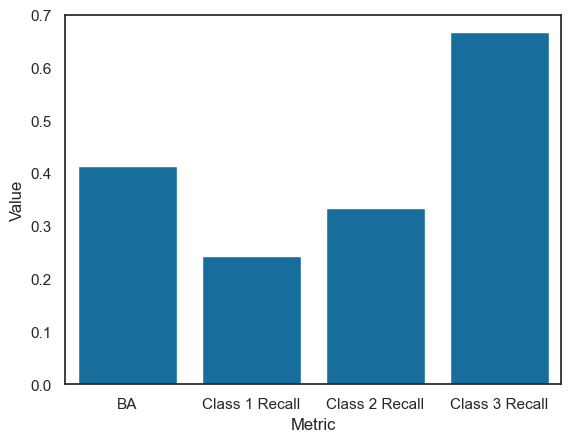

In [12]:
sns.barplot(
    pd.DataFrame(
        {
            "Metric": ["BA", "Class 1 Recall", "Class 2 Recall", "Class 3 Recall"],
            "Value": [balanced_accuracy_score(y_test, y_pred_ext)]
            + recall_score(y_test, y_pred_ext, average=None).tolist(),
        }
    ),
    x="Metric",
    y="Value",
)

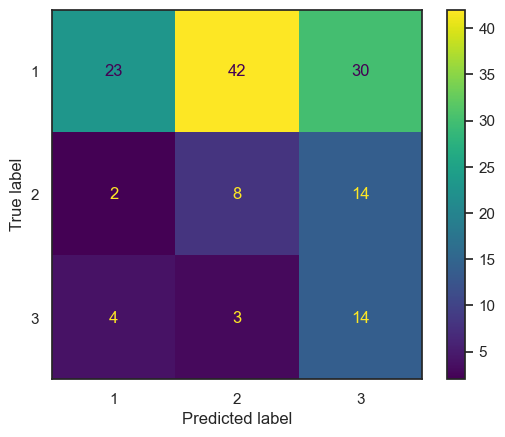

In [13]:
cm = confusion_matrix(
    y_true=y_test,
    y_pred=y_pred_ext,
    labels=[1, 2, 3],
)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[1, 2, 3])
disp.plot()

### <span style="color:black"> <b><center> End of the notebook </span></b></center> <a id='test_configuration_file'></a>
***
!-- [Back to Index](#Index) -->